In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 
import tol_colors as tc

import tools
import my_plot as mplt

from plot_utils import set_size, set_colors, width_jcap, sci_formatter
plt.style.use('my_style.mplstyle')

In [2]:
theta_bar = 1.7*1e-6

In [3]:
plt.rcParams['font.size']=14
colors = set_colors(4, palette="colorblind")
colors2 = tc.colorsets['vibrant']

In [4]:
def extract_PS(folder_path, ellmax, ymax, zcon):
    """Extract power spectra from the output of the FH code. """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_nmax_{zcon}.dat"))
    file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_zcon_{zcon}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}.dat"))

    ell = []
    TT = []
    muT = []
    yT = []
    deltaTT = []
    EE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TT = np.loadtxt(file_path, comments='#')[:, 1]
    deltaTT = np.loadtxt(file_path, comments='#')[:, 3]
    muT = np.loadtxt(file_path, comments='#')[:, 4]
    yT = np.loadtxt(file_path, comments='#')[:, 5]
    EE = np.loadtxt(file_path, comments='#')[:, 6]

    return np.array(ell), np.array(TT), np.array(EE), np.array(yT), np.array(muT), np.array(deltaTT)

In [5]:
def extract_PS2(folder_path, ellmax, ymax, zcon):
    """Extract power spectra from the output of the FH code. """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_nmax_{zcon}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_zcon_{zcon}.dat"))
    file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic.dat"))

    ell = []
    TT = []
    muT = []
    yT = []
    deltaTT = []
    EE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TT = np.loadtxt(file_path, comments='#')[:, 1]
    deltaTT = np.loadtxt(file_path, comments='#')[:, 3]
    muT = np.loadtxt(file_path, comments='#')[:, 4]
    yT = np.loadtxt(file_path, comments='#')[:, 5]
    EE = np.loadtxt(file_path, comments='#')[:, 6]

    return np.array(ell), np.array(TT), np.array(EE), np.array(yT), np.array(muT), np.array(deltaTT)

In [6]:
ell, TT, EE, yT, muT, deltaTT = extract_PS("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"001")
_ , _ , _ , yT_1, muT_1, deltaTT_1 = extract_PS("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"002")
_ , _ , _ , yT_2, muT_2, deltaTT_2 = extract_PS("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"003")
_ , _ , _ , yT_3, muT_3, deltaTT_3 = extract_PS("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"004")


# ell, TT, EE, yT, muT, deltaTT = extract_PS("../Data/Dark-photons/PS-Jens/","001")
# _ , _ , _ , yT_1, muT_1, deltaTT_1 = extract_PS("../Data/Dark-photons/PS-Jens/","002")
# _ , _ , _ , yT_2, muT_2, deltaTT_2 = extract_PS("../Data/Dark-photons/PS-Jens/","003")
# _ , _ , _ , yT_3, muT_3, deltaTT_3 = extract_PS("../Data/Dark-photons/PS-Jens/","004")


ell, TT_approx, EE_approx, yT_approx, muT_approx, deltaTT_approx = extract_PS("../Data/Dark-photons/outputs_dp_PS-approx/batch/",15,5,"001")
_ , _ , _ , yT_1_approx, muT_1_approx, deltaTT_1_approx = extract_PS("../Data/Dark-photons/outputs_dp_PS-approx/batch/",15,5,"002")
_ , _ , _ , yT_2_approx, muT_2_approx, deltaTT_2_approx = extract_PS("../Data/Dark-photons/outputs_dp_PS-approx/batch/",15,5,"003")
_ , _ , _ , yT_3_approx, muT_3_approx, deltaTT_3_approx = extract_PS("../Data/Dark-photons/outputs_dp_PS-approx/batch/",15,5,"004")



In [7]:
# _ , _ , _ , yT_3, muT_3, deltaTT_3 = extract_PS2("../Data/Dark-photons/outputs-dp1.3_PStest/",15,15,"004")


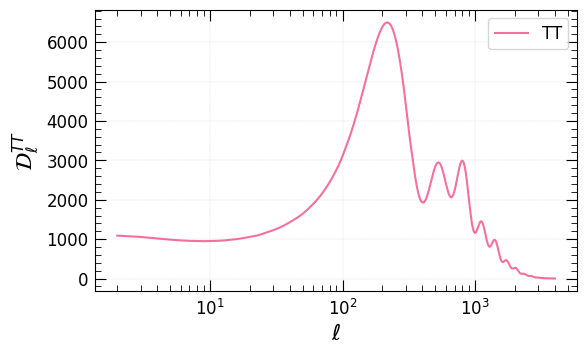

In [8]:


fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap))
ax.plot(ell, TT, color=colors2[3], alpha=0.7, linestyle="-", label="TT")
ax.set_xscale('log')
ax.set_xlabel("$\\ell$")
ax.set_ylabel("$\\mathcal{D}_\\ell^{{TT}}$")
ax.legend()
plt.show()


The following two plots are for me only, we are not including the first line in the paper. But they nicely show how very early energy injections thermalise immediatly, what we see it is basically only a very small signal due to numerical noise probably

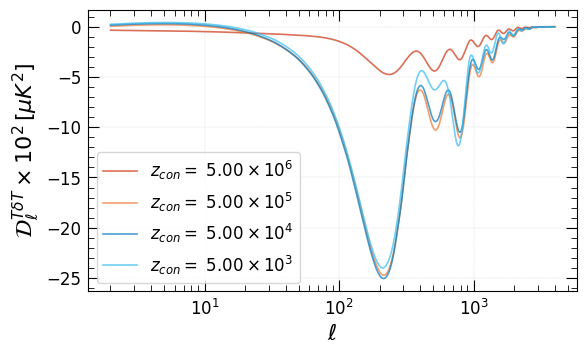

In [9]:

fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap))

ax.plot(ell, 2*deltaTT*100, color=colors2[4], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")

ax.plot(ell, 2*deltaTT_1*100, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e5)}")
ax.plot(ell, 2*deltaTT_2*100, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e4)}")
ax.plot(ell, 2*deltaTT_3*100, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e3)}")

ax.set_xlabel("$\\ell$")
ax.set_ylabel("$\\mathcal{D}_{\\ell}^{{T \\delta T}} \\times 10^2 \\, [\\mu K^2]$")
ax.set_xscale('log')
ax.set_yscale('linear')
ax.legend()

plt.savefig('outputs/TTcorr.pdf', dpi=300, bbox_inches="tight")
plt.show()


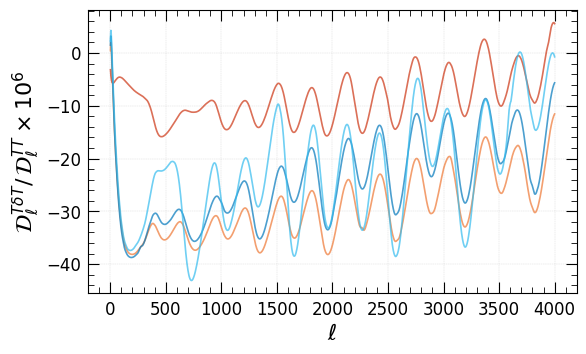

In [10]:
fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap))

ax.plot(ell, 2*deltaTT/TT/1e-6, color=colors2[4], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")
ax.plot(ell, 2*deltaTT_1/TT/1e-6, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e5)}")
ax.plot(ell, 2*deltaTT_2/TT/1e-6, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e4)}")
ax.plot(ell, 2*deltaTT_3/TT/1e-6, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e3)}")

ax.set_xlabel("$\\ell$")
ax.set_ylabel("$ \\mathcal{D}_{\\ell}^{{T \\delta T}} / \\, \\mathcal{D}_{\\ell}^{{TT}} \\times 10^6 $")
ax.set_xscale('linear')
ax.set_yscale('linear')


plt.savefig('outputs/TTcorr_TT.pdf', dpi=300, bbox_inches="tight")
plt.show()

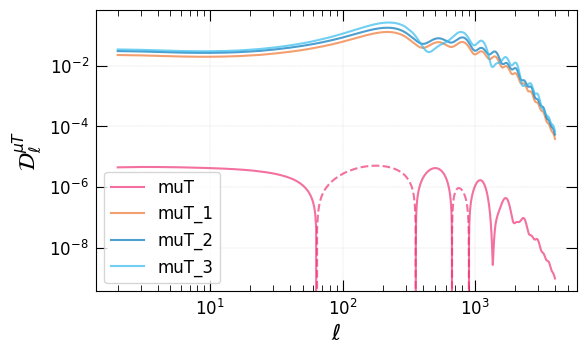

In [11]:

fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap))

ax.plot(ell, muT, color=colors2[3], alpha=0.7, linestyle="-", label="muT")
ax.plot(ell, -muT, color=colors2[3], alpha=0.7, linestyle="--")

ax.plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", label="muT_1")
ax.plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", label="muT_2")
ax.plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", label="muT_3")

ax.set_xlabel("$\\ell$")
ax.set_ylabel("$\\mathcal{D}_{\\ell}^{{\\mu T}} $")
ax.set_xscale('log')
ax.set_yscale('log')

ax.legend()
plt.show()

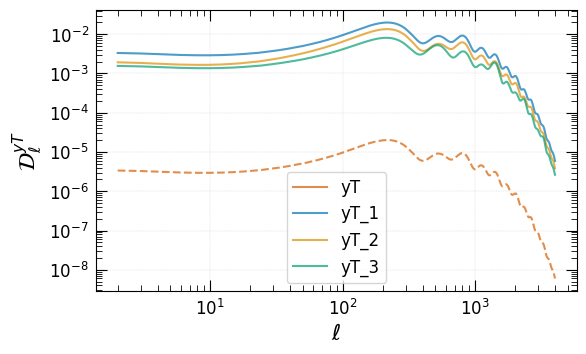

In [12]:

fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap))

ax.plot(ell, yT, color=colors[3], alpha=0.7, linestyle="-", label="yT")
ax.plot(ell, -yT, color=colors[3], alpha=0.7, linestyle="--")


ax.plot(ell, yT_1, color=colors[0], alpha=0.7, linestyle="-", label="yT_1")
ax.plot(ell, yT_2, color=colors[1], alpha=0.7, linestyle="-", label="yT_2")
ax.plot(ell, yT_3, color=colors[2], alpha=0.7, linestyle="-", label="yT_3")


ax.set_xlabel("$\\ell$")
ax.set_ylabel("$\\mathcal{D}_{\\ell}^{{y T }} $")
ax.set_xscale('log')
ax.set_yscale('log')

ax.legend()
plt.show()

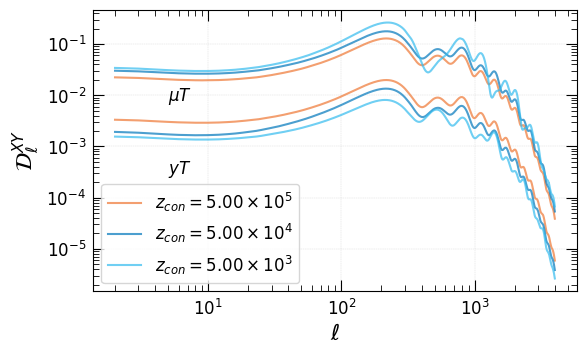

In [13]:
fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap))



ax.plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax.plot(ell, yT_1, color=colors2[0], alpha=0.7, linestyle="-")
ax.plot(ell, yT_2, color=colors2[1], alpha=0.7, linestyle="-")
ax.plot(ell, yT_3, color=colors2[2], alpha=0.7, linestyle="-")


ax.set_xlabel("$\\ell$")
ax.set_ylabel("$\\mathcal{D}_{\\ell}^{{XY}} $")
ax.set_xscale('log')
ax.set_yscale('log')

ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
ax.annotate("$\\mu T$", xy=(5, 8e-3), fontsize=12)



ax.legend()
plt.show()

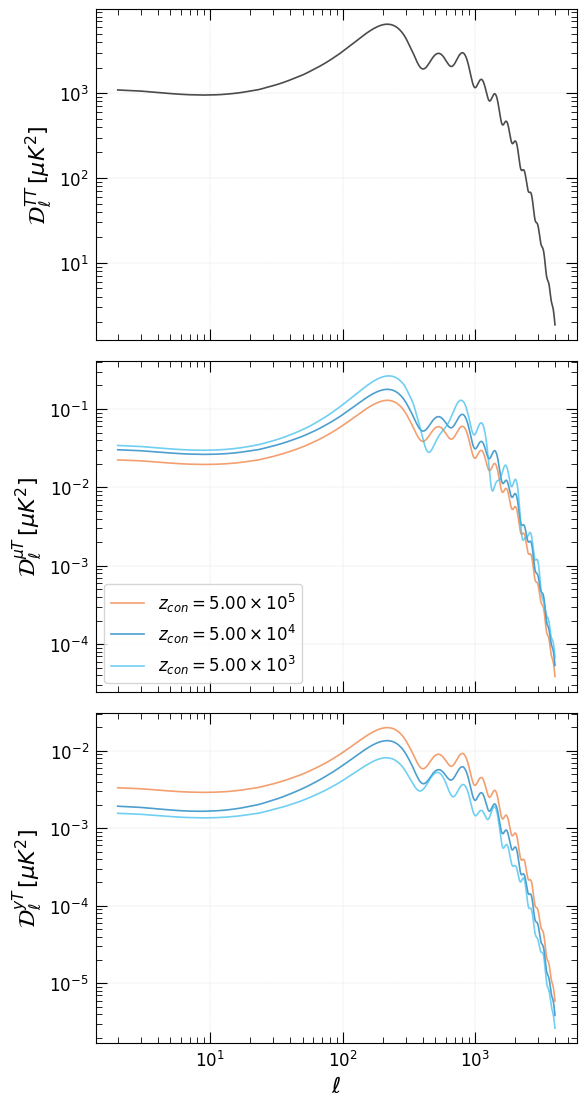

In [14]:
fig, ax = plt.subplots(3, 1, figsize=set_size(width_jcap, 1, (3,1)), sharex='col')

ax[0].plot(ell, TT, color="black", linewidth=1.2, alpha=0.7, linestyle="-", label="TT")
# ax[0].plot(ell, TT_approx, color=colors2[4], linewidth=1.2, alpha=0.7, linestyle="--")



ax[1].plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax[1].plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax[1].plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

# ax[1].plot(ell, muT_1_approx, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[1].plot(ell, muT_2_approx, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[1].plot(ell, muT_3_approx, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)

ax[2].plot(ell, yT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2)
ax[2].plot(ell, yT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2)
ax[2].plot(ell, yT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2)

# ax[2].plot(ell, yT_1_approx, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, yT_2_approx, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, yT_3_approx, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)

#ax[2].plot(ell, 2*deltaTT, color=colors2[3], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")
# ax[2].plot(ell, 2*deltaTT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e5)}")
# ax[2].plot(ell, 2*deltaTT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e4)}")
# ax[2].plot(ell, 2*deltaTT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e3)}")


# ax[2].plot(ell, 2*deltaTT, color=colors2[3], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")
# ax[2].plot(ell, 2*deltaTT_1_approx, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_2_approx, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_3_approx, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)


for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')

ax[0].tick_params(labelbottom=False)
ax[1].tick_params(labelbottom=False)

ax[0].set_ylabel("$\\mathcal{D}_\\ell^{{TT}} \\, [\\mu K^2]$")
ax[1].set_ylabel("$\\mathcal{D}_{\\ell}^{{\\mu T}} \\, [\\mu K^2]$")
ax[2].set_ylabel("$\\mathcal{D}_{\\ell}^{{y T}} \\, [\\mu K^2]$")
ax[2].set_xlabel("$\\ell$")

ax[1].legend()


plt.savefig('outputs/muT_yT.pdf', dpi=300, bbox_inches="tight")
plt.show()

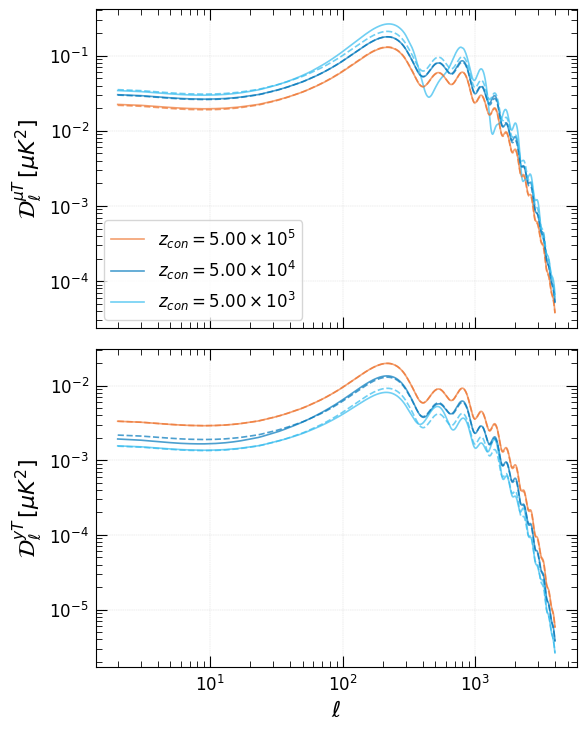

In [15]:
fig, ax = plt.subplots(2, 1, figsize=set_size(width_jcap, 1, (2,1)), sharex='col')

# ax[0].plot(ell, TT, color="black", linewidth=1.2, alpha=0.7, linestyle="-", label="TT")
# ax[0].plot(ell, TT_approx, color=colors2[4], linewidth=1.2, alpha=0.7, linestyle="--")



ax[0].plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax[0].plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax[0].plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax[0].plot(ell, muT_1_approx, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
ax[0].plot(ell, muT_2_approx, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
ax[0].plot(ell, muT_3_approx, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)

ax[1].plot(ell, yT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2)
ax[1].plot(ell, yT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2)
ax[1].plot(ell, yT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2)

ax[1].plot(ell, yT_1_approx, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
ax[1].plot(ell, yT_2_approx, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
ax[1].plot(ell, yT_3_approx, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)

#ax[2].plot(ell, 2*deltaTT, color=colors2[3], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")
# ax[2].plot(ell, 2*deltaTT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e5)}")
# ax[2].plot(ell, 2*deltaTT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e4)}")
# ax[2].plot(ell, 2*deltaTT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e3)}")


# ax[2].plot(ell, 2*deltaTT, color=colors2[3], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")
# ax[2].plot(ell, 2*deltaTT_1_approx, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_2_approx, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_3_approx, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)

for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')

ax[0].tick_params(labelbottom=False)

ax[1].set_xlabel("$\\ell$")
ax[0].set_ylabel("$\\mathcal{D}_{\\ell}^{{\\mu T}} \\, [\\mu K^2]$")
ax[1].set_ylabel("$\\mathcal{D}_{\\ell}^{{y T}} \\, [\\mu K^2]$")

ax[0].legend()

plt.savefig('outputs/muT_yT_approx.pdf', dpi=300, bbox_inches="tight")
plt.show()

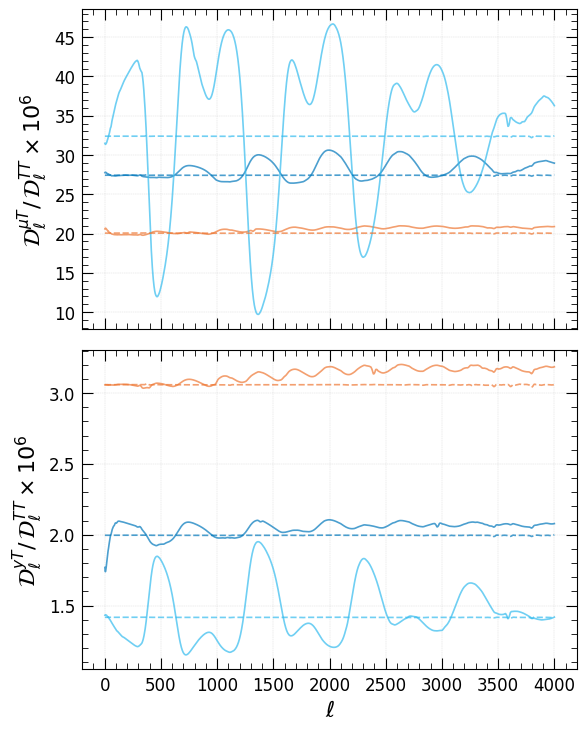

In [16]:
fig, ax = plt.subplots(2, 1, figsize=set_size(width_jcap, 1, (2,1)), sharex='col')



ax[0].plot(ell, muT_1/TT/1e-6, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax[0].plot(ell, muT_2/TT/1e-6, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax[0].plot(ell, muT_3/TT/1e-6, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax[0].plot(ell, muT_1_approx/TT/1e-6, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
ax[0].plot(ell, muT_2_approx/TT/1e-6, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
ax[0].plot(ell, muT_3_approx/TT/1e-6, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)

ax[1].plot(ell, yT_1/TT/1e-6, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2)
ax[1].plot(ell, yT_2/TT/1e-6, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2)
ax[1].plot(ell, yT_3/TT/1e-6, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2)

ax[1].plot(ell, yT_1_approx/TT/1e-6, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
ax[1].plot(ell, yT_2_approx/TT/1e-6, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
ax[1].plot(ell, yT_3_approx/TT/1e-6, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)



# ax[2].plot(ell, 2*deltaTT_1_approx/TT/1e-6, color=colors2[0], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_2_approx/TT/1e-6, color=colors2[1], alpha=0.7, linestyle="--", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_3_approx/TT/1e-6, color=colors2[2], alpha=0.7, linestyle="--", linewidth=1.2)


ax[0].tick_params(labelbottom=False)

ax[1].set_xlabel("$\\ell$")
ax[0].set_ylabel("$\\mathcal{D}_{\\ell}^{{\\mu T}} / \\, \\mathcal{D}_{\\ell}^{{TT}} \\times 10^6$")
ax[1].set_ylabel("$\\mathcal{D}_{\\ell}^{{y T}} / \\, \\mathcal{D}_{\\ell}^{{TT}} \\times 10^6$")

plt.savefig('outputs/muT_yT_TT.pdf', dpi=300, bbox_inches="tight")
plt.show()

In [17]:
ell_noS1, TT_noS1, _, yT_noS1, muT_noS1, deltaTT_noS1 = extract_PS("../Data/Dark-photons/outputs_dp_PS-batch-noS1/batch/",15,5,"001")
_ , _ , _ , yT_1_noS1, muT_1_noS1, deltaTT_1_noS1 = extract_PS("../Data/Dark-photons/outputs_dp_PS-batch-noS1/batch/",15,5,"002")
_ , _ , _ , yT_2_noS1, muT_2_noS1, deltaTT_2_noS1 = extract_PS("../Data/Dark-photons/outputs_dp_PS-batch-noS1/batch/",15,5,"003")
_ , _ , _ , yT_3_noS1, muT_3_noS1, deltaTT_3_noS1 = extract_PS("../Data/Dark-photons/outputs_dp_PS-batch-noS1/batch/",15,5,"004")

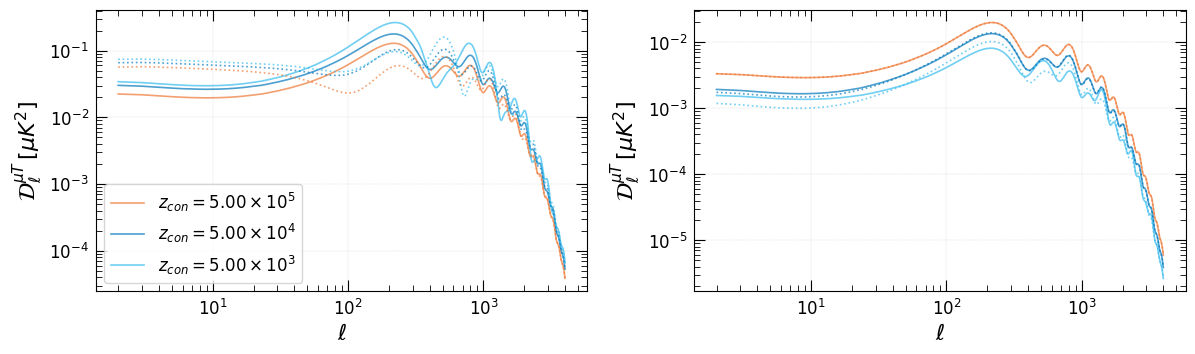

In [18]:
fig, ax = plt.subplots(1, 2, figsize=set_size(width_jcap*2, 1, (1,2)), sharex='col')

# ax[0].plot(ell, TT, color="black", linewidth=1.2, alpha=0.7, linestyle="-", label="TT")
# ax[0].plot(ell, TT_approx, color=colors2[4], linewidth=1.2, alpha=0.7, linestyle="--")



ax[0].plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax[0].plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax[0].plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax[0].plot(ell, muT_1_noS1, color=colors2[0], alpha=0.7, linestyle="dotted", linewidth=1.2)
ax[0].plot(ell, muT_2_noS1, color=colors2[1], alpha=0.7, linestyle="dotted", linewidth=1.2)
ax[0].plot(ell, muT_3_noS1, color=colors2[2], alpha=0.7, linestyle="dotted", linewidth=1.2)

ax[1].plot(ell, yT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2)
ax[1].plot(ell, yT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2)
ax[1].plot(ell, yT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2)

ax[1].plot(ell, yT_1_noS1, color=colors2[0], alpha=0.7, linestyle="dotted", linewidth=1.2)
ax[1].plot(ell, yT_2_noS1, color=colors2[1], alpha=0.7, linestyle="dotted", linewidth=1.2)
ax[1].plot(ell, yT_3_noS1, color=colors2[2], alpha=0.7, linestyle="dotted", linewidth=1.2)

#ax[2].plot(ell, 2*deltaTT, color=colors2[3], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")
# ax[2].plot(ell, 2*deltaTT_1, color=colors2[0], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e5)}")
# ax[2].plot(ell, 2*deltaTT_2, color=colors2[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e4)}")
# ax[2].plot(ell, 2*deltaTT_3, color=colors2[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e3)}")


# ax[2].plot(ell, 2*deltaTT, color=colors2[3], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} =$ {tools.sci_notation(5e6)}")
# ax[2].plot(ell, 2*deltaTT_1_noS1, color=colors2[0], alpha=0.7, linestyle="dotted", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_2_noS1, color=colors2[1], alpha=0.7, linestyle="dotted", linewidth=1.2)
# ax[2].plot(ell, 2*deltaTT_3_noS1, color=colors2[2], alpha=0.7, linestyle="dotted", linewidth=1.2)



for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')



ax[0].set_xlabel("$\\ell$")
ax[1].set_xlabel("$\\ell$")
ax[0].set_ylabel("$\\mathcal{D}_{\\ell}^{{\\mu T}} \\, [\\mu K^2]$")
ax[1].set_ylabel("$\\mathcal{D}_{\\ell}^{{\\mu T}} \\, [\\mu K^2]$")

ax[0].legend()


plt.savefig('outputs/muT_yT_noS1.pdf', dpi=300, bbox_inches="tight")

plt.show()

In [19]:
def extract_PS_batch(folder_path, index_max):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" / "yn_T_aniso_system" 

    ellT = []
    TT = []
    muT = []
    yT = []
    deltaTT = []

    
    for i in range(index_max):
        file_path = next(folder.glob(f"power_spectra_ymax15_lmax15_adiabatic_zcon_{i+1:03d}.dat"))

        if i == 0:
            ellT.append(np.loadtxt(file_path, comments='#')[:, 0])

        TT.append(np.loadtxt(file_path, comments='#')[:, 1])
        muT.append(np.loadtxt(file_path, comments='#')[:, 4])
        yT.append(np.loadtxt(file_path, comments='#')[:, 5])
        deltaTT.append(np.loadtxt(file_path, comments='#')[:, 3])
        

    return np.array(ellT), np.array(TT),np.array(yT), np.array(muT), np.array(deltaTT)


In [20]:
#ell_batch , TT_batch , yT_batch, muT_batch= extract_PS_batch("../Data/Dark-photons/outputs-dp_PSbatch/",15)
ell_batch , TT_batch , yT_batch, muT_batch , deltaTT_batch = extract_PS_batch("../Data/Dark-photons/outputs_dp_PS-fullbatch",6)


In [21]:
def truncated_cmap(cmap_name, minval=0.1, maxval=0.9, n=15):
    cmap = plt.matplotlib.colormaps[cmap_name]
    return lambda i: cmap(minval + (maxval - minval) * i / (n - 1))

# colors = truncated_cmap("plasma", 0, 0.9, 15)  # vibrant rainbow

colors = tc.rainbow_PuRd.resampled(6)
#colors = tc.sunset_discrete.resampled(15)

In [22]:
zcon = np.geomspace(5e3, 1e6,num=15)

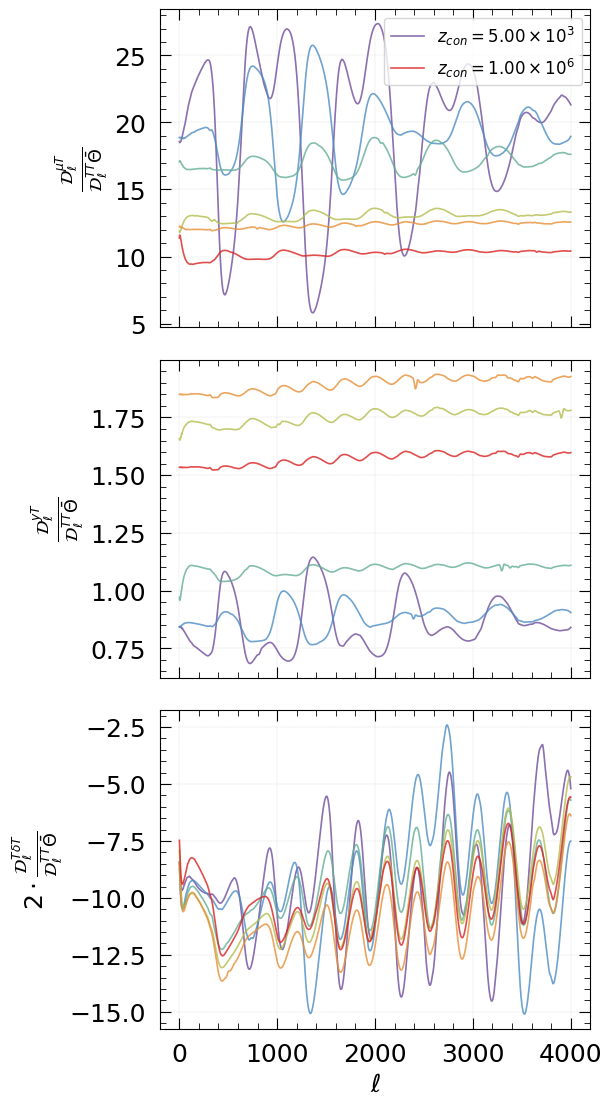

In [23]:
lines =[]


fig, ax = plt.subplots(3, 1, figsize=set_size(width_jcap, 1, (3,1)), sharex='col')

for i in range(len(TT_batch)):
        line = ax[0].plot(ell_batch[0], muT_batch[i]/TT_batch[i]/theta_bar, color=colors(i), alpha=0.8, linestyle="-", linewidth=1.2)
        lines.append(line[0])  # plot returns a list

# Set labels manually for first and last
if lines:
    lines[0].set_label(f"$z_{{con}}=${tools.sci_notation(zcon[0])}")
    lines[-1].set_label(f"$z_{{con}}=${tools.sci_notation(zcon[14])}")


for i in range(len(TT_batch)):
        ax[1].plot(ell_batch[0], yT_batch[i]/TT_batch[i]/theta_bar, color=colors(i), alpha=0.8, linestyle="-", linewidth=1.2)

for i in range(len(TT_batch)):
        ax[2].plot(ell_batch[0], 2*deltaTT_batch[i]/TT_batch[i]/theta_bar, color=colors(i), alpha=0.8, linestyle="-", linewidth=1.2)

mplt.set_ticks(ax[0])
mplt.set_labels(ax[0], x_label=None, x_log=False, y_label="$\\frac{\\mathcal{D}_{\\ell}^{{\\mu T}}}{\\mathcal{D}_{\\ell}^{{TT}} \\bar{\\Theta}}$", y_log=False, title=None)

ax[0].grid(which='minor', visible=False)
ax[0].legend()

mplt.set_ticks(ax[1])
mplt.set_labels(ax[1], x_label=None, x_log=False, y_label="$\\frac{\\mathcal{D}_{\\ell}^{{y T}}}{\\mathcal{D}_{\\ell}^{{TT}} \\bar{\\Theta}}$", y_log=False, title=None)

ax[1].grid(which='minor', visible=False)

mplt.set_ticks(ax[2])
mplt.set_labels(ax[2], x_label="$\\ell$", x_log=False, y_label="$2 \\cdot \\frac{\\mathcal{D}_{\\ell}^{{T \\delta T}}}{\\mathcal{D}_{\\ell}^{{TT}} \\bar{\\Theta}}$", y_log=False, title=None)

ax[2].grid(which='minor', visible=False)

ax[0].tick_params(labelbottom=False)
ax[1].tick_params(labelbottom=False)



plt.tight_layout()

plt.savefig('outputs/XT-batch.pdf', dpi=300, bbox_inches="tight")

plt.show()

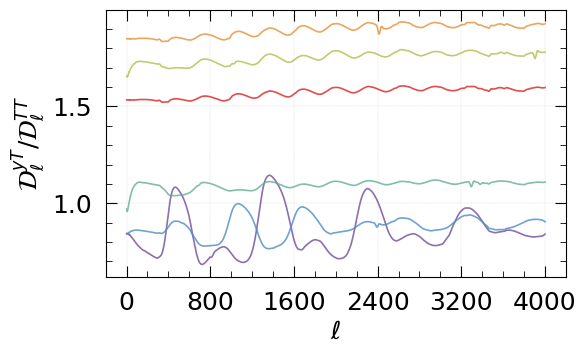

In [24]:
fig, ax = plt.subplots(1, 1, figsize=set_size(width_jcap))


for i in range(len(TT_batch)):
        line = ax.plot(ell_batch[0], yT_batch[i]/TT_batch[i]/theta_bar, color=colors(i), alpha=0.8, linestyle="-", linewidth=1.2)
        lines.append(line[0])  # plot returns a list

# Set labels manually for first and last
if lines:
    lines[0].set_label(f"$z_{{con}}=${tools.sci_notation(zcon[0])}")
    lines[-1].set_label(f"$z_{{con}}=${tools.sci_notation(zcon[14])}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{y T}} / \\mathcal{D}_{\\ell}^{{TT}}$", y_log=False, title=None)

# ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu T$", xy=(5, 2e-2), fontsize=12)

plt.savefig('outputs/yT-batch.pdf', dpi=300, bbox_inches="tight")
ax.grid(which='minor', visible=False)


plt.show()

In [25]:
def extract_PS_ISO(folder_path, index_max):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" / "yn_aniso_system" 

    ellT = []
    TT = []
    muT = []
    yT = []
    deltaTT = []

    
    for i in range(index_max):
        file_path = next(folder.glob(f"power_spectra_ymax15_lmax15_adiabatic_zcon_{i+1:03d}.dat"))
        

        if i == 0:
            ellT.append(np.loadtxt(file_path, comments='#')[:, 0])

        TT.append(np.loadtxt(file_path, comments='#')[:, 1])
        muT.append(np.loadtxt(file_path, comments='#')[:, 4])
        yT.append(np.loadtxt(file_path, comments='#')[:, 5])
        deltaTT.append(np.loadtxt(file_path, comments='#')[:, 3])
        

    return np.array(ellT), np.array(TT),np.array(yT), np.array(muT), np.array(deltaTT)